### Outlier Removal Using Z-Score

An **outlier** is an observation that is unusually far from most other values in a feature. Outliers may occur because of data-entry errors, measurement problems, or genuine rare events.

This notebook uses the **Z-score method** to identify unusual values in the `cgpa` feature, then demonstrates two treatments:
- **Trimming :** remove rows outside the selected limits.
- **Capping (Winsorization) :** replace values outside the limits with the nearest boundary value.

Before removing an outlier, investigate whether it is an error or a valid observation. Outliers are not automatically bad data.

#### What is a Z-score ?

A Z-score tells us how many standard deviations a value is above or below the feature mean.

$
z = \frac{x-\mu}{\sigma}
$

Where:
- $x$ = observed value
- $mu$ = mean of the feature
- $sigma$ = standard deviation of the feature

A common rule for approximately normally distributed data is:
- $z > 3$: unusually high value
- $z < -3$: unusually low value
- $-3 \le z \le 3$: within the commonly used range

The equivalent boundaries are $mu \pm 3\sigma$. This is a heuristic, not a universal rule; the method can be misleading for skewed or non-normal distributions.

**When to Use :** When data follows `Normal Distribution`

**Important :** Z-score detection assumes the mean and standard deviation are meaningful summaries. For heavily skewed data, consider robust methods such as IQR-based detection or transformations, rather than applying the ±3 rule blindly.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('Datasets/placement.csv')

In [3]:
df.shape

(1000, 3)

In [4]:
df.sample(5)

,cgpa,placement_exam_marks,placed
743,7.62,15.0,1
416,7.51,55.0,1
14,7.91,43.0,0
176,7.72,30.0,1
551,6.55,66.0,1


C:\Users\us\AppData\Local\Temp\ipykernel_1668\3792736820.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['cgpa'])
C:\Users\us\AppData\Local\Temp\ipykernel_1668\3792736820.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['placement_exam_marks'])


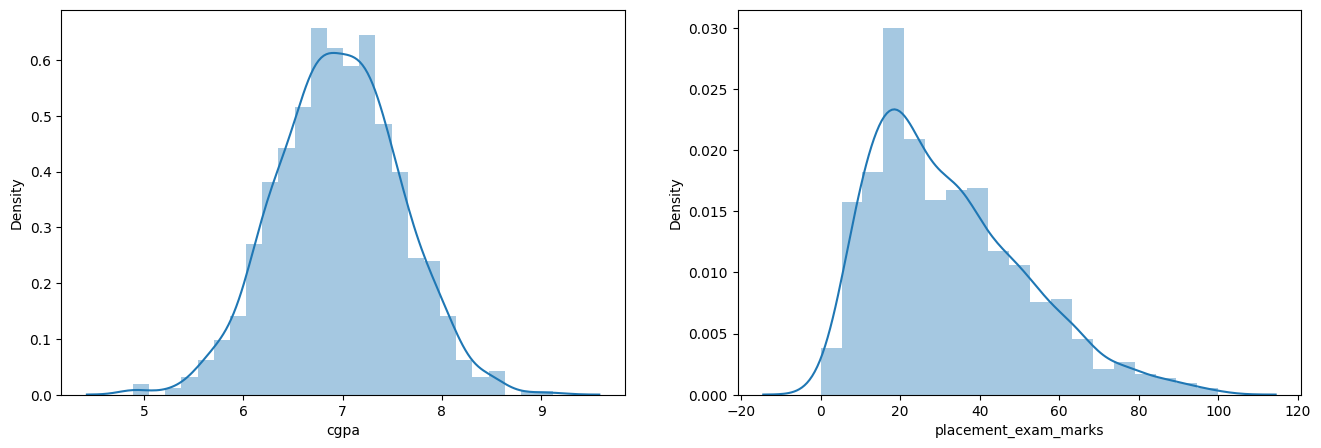

In [5]:
plt.figure(figsize=(16,5))
plt.subplot(1,2,1)
sns.distplot(df['cgpa'])

plt.subplot(1,2,2)
sns.distplot(df['placement_exam_marks'])

plt.show()

In [6]:
df['placement_exam_marks'].skew()

np.float64(0.8356419499466834)

In [7]:
print("Mean value of cgpa",df['cgpa'].mean())
print("Std value of cgpa",df['cgpa'].std())
print("Min value of cgpa",df['cgpa'].min())
print("Max value of cgpa",df['cgpa'].max())

Mean value of cgpa 6.96124
Std value of cgpa 0.6158978751323896
Min value of cgpa 4.89
Max value of cgpa 9.12


In [8]:
# Finding the boundary values
print("Highest allowed",df['cgpa'].mean() + 3*df['cgpa'].std())
print("Lowest allowed",df['cgpa'].mean() - 3*df['cgpa'].std())

Highest allowed 8.808933625397168
Lowest allowed 5.113546374602832


In [9]:
# Finding the outliers
df[(df['cgpa'] > 8.80) | (df['cgpa'] < 5.11)]

,cgpa,placement_exam_marks,placed
485,4.92,44.0,1
995,8.87,44.0,1
996,9.12,65.0,1
997,4.89,34.0,0
999,4.90,10.0,1


### Trimming

**Trimming** removes entire rows whose feature values fall outside the lower and upper limits.

In this notebook, rows are retained only when `cgpa` is between the limits (approximately 5.11 and 8.80).

**Advantages**
- Removes extreme observations that may strongly influence some models.
- Can simplify analysis when extreme values are confirmed errors.

**Disadvantages**
- Removes data and reduces sample size.
- Can discard valid rare observations and introduce bias.
- A threshold chosen from one feature may not suit other features.

**Use when :** extreme values are errors or are outside the population you intend to model, and removing those rows is justified.

In [10]:
# Trimming

new_df = df[(df['cgpa'] < 8.80) & (df['cgpa'] > 5.11)]
new_df

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0
...,...,...,...
991,7.04,57.0,0
992,6.26,12.0,0
993,6.73,21.0,1
994,6.48,63.0,0


In [11]:
# Approach 2

# Calculating the Zscore

df['cgpa_zscore'] = (df['cgpa'] - df['cgpa'].mean())/df['cgpa'].std()

In [12]:
df.head()

,cgpa,placement_exam_marks,placed,cgpa_zscore
0,7.19,26.0,1,0.371425
1,7.46,38.0,1,0.809810
2,7.54,40.0,1,0.939701
3,6.42,8.0,1,-0.878782
4,7.23,17.0,0,0.436371


In [13]:
df[df['cgpa_zscore'] > 3]

,cgpa,placement_exam_marks,placed,cgpa_zscore
995,8.87,44.0,1,3.099150
996,9.12,65.0,1,3.505062


In [14]:
df[df['cgpa_zscore'] < -3]

,cgpa,placement_exam_marks,placed,cgpa_zscore
485,4.92,44.0,1,-3.314251
997,4.89,34.0,0,-3.362960
999,4.90,10.0,1,-3.346724


In [16]:
# outliers 
df[(df['cgpa_zscore'] > 3) | (df['cgpa_zscore'] < -3)]

,cgpa,placement_exam_marks,placed,cgpa_zscore
485,4.92,44.0,1,-3.314251
995,8.87,44.0,1,3.099150
996,9.12,65.0,1,3.505062
997,4.89,34.0,0,-3.362960
999,4.90,10.0,1,-3.346724


In [17]:
# Trimming 
new_df = df[(df['cgpa_zscore'] < 3) & (df['cgpa_zscore'] > -3)]

In [18]:
new_df

,cgpa,placement_exam_marks,placed,cgpa_zscore
0,7.19,26.0,1,0.371425
1,7.46,38.0,1,0.809810
2,7.54,40.0,1,0.939701
3,6.42,8.0,1,-0.878782
4,7.23,17.0,0,0.436371
...,...,...,...,...
991,7.04,57.0,0,0.127878
992,6.26,12.0,0,-1.138565
993,6.73,21.0,1,-0.375452
994,6.48,63.0,0,-0.781363


### Capping (Winsorization)

**Capping** keeps all rows but replaces values below the lower limit with the lower limit, and values above the upper limit with the upper limit.

This reduces the influence of extreme values without deleting observations.

**Advantages**
- Preserves the number of rows.
- Limits the impact of extreme values on sensitive models.

**Disadvantages**
- Changes the original values and compresses the tails of the distribution.
- Can hide meaningful extreme events.
- May create many identical values at the boundaries.

**Use when :** extreme values are valid but their magnitude should be limited for a particular analysis or model.

In [19]:
upper_limit = df['cgpa'].mean() + 3*df['cgpa'].std()
lower_limit = df['cgpa'].mean() - 3*df['cgpa'].std()

In [20]:
lower_limit

np.float64(5.113546374602832)

In [21]:
df['cgpa'] = np.where(
    df['cgpa']>upper_limit,
    upper_limit,
    np.where(
        df['cgpa']<lower_limit,
        lower_limit,
        df['cgpa']
    )
)

In [22]:
df.shape

(1000, 4)

In [23]:
df['cgpa'].describe()

count    1000.000000
mean        6.961499
std         0.612688
min         5.113546
25%         6.550000
50%         6.960000
75%         7.370000
max         8.808934
Name: cgpa, dtype: float64

### How outliers affect different algorithms ?

Outlier sensitivity depends on the algorithm and the feature representation. This is a general guide:

| Algorithm | Sensitivity to outliers | Why |
|---|---|---|
| Linear Regression | High | Squared errors make large residuals influential; extreme feature values can have high leverage. |
| Logistic Regression | Moderate to high | Extreme feature values can strongly affect fitted coefficients and decision boundaries. |
| KNN | High | Distance calculations can be dominated by extreme values and affect nearest neighbours. |
| K-Means | High | Centroids are means, so extreme points can pull cluster centres. |
| SVM (especially RBF/kernel) | Moderate to high | Outliers can influence the margin and support-vector selection. |
| Decision Tree | Generally lower | Splits depend on feature thresholds, not distances or means, though extreme values can still affect split choices. |
| Random Forest | Generally lower | Tree-based ensemble; usually less sensitive than distance- or mean-based methods, but not immune. |
| Gradient Boosting Trees / XGBoost | Generally lower to moderate | Tree splits are relatively robust, but extreme targets or noisy points can still affect learning. |
| Naive Bayes | Depends on variant | Gaussian Naive Bayes estimates means and variances, which outliers can distort; other variants behave differently. |
| Neural Networks | Often sensitive | Large input values can cause unstable optimization or dominate gradients without suitable scaling/robust preprocessing. |

**Key idea :** Distance-based and mean/squared-error-based methods are often more affected by outliers. Tree-based methods are usually more robust, but no algorithm is completely immune.